# Experimentation
---
In this notebook, we experiment with different functino settings, base data, files, concepts and visualisations. The goal is to find the best way to convey the findings of our research, both in terms of visualisation, but also in terms of metrics which are used for the communication.

In [19]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

from kiln_ring_analysis_function import kiln_ring_analysis, DEFAULTS as ANALYSIS_DEFAULTS
from plot_kiln_rings_function import plot_kiln_rings, DEFAULTS as PLOT_DEFAULTS

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


***
## Display raw data
In this chapter we will start with 16 rays, 1m sample intervals and 6m ring intervals (up to 24m). The samples are not weighted.  

The analysis results are saved in: `new testfolder/results/merged_dem_rays16_step1_ring6x4`

### Run analysis

In [20]:
params = {
    "gpkg": "kohlmeiler_2056.gpkg",
    "tif": "merged_dem.tif",
    "rings": [(0, 6), (6, 12), (12, 18), (18, 24)],
    "n_rays": 16,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

samples = pd.read_csv("results/merged_dem_rays16_step1_ring6x4/merged_dem_samples.csv")
rings = [(0, 6), (6, 12), (12, 18), (18, 24)]

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          16 (every 22.5°), sample every 1 m up to 24 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 96 samples
       6-12    m: 96 samples
      12-18    m: 96 samples
      18-24    m: 96 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m
count   79.00   79.00    79.00    79.00
median   6.20    5.93     6.14     6.06
mean     6.73    6.45     6.39     6.53
std      3.88    3.55     3.50     3.37
min      0.00    0.00     0.00     0.19
25%      4.66    4.60     4.23     4.79
50%      6.20    5.93     6.14     6.06
75%      8.54    8.56     7.47     7.86
max     19.02   16.17    17.76    17.15

Rings left empty (too little valid data):
   mean_0_6: kilns [12]
   mean_6_12: kiln

### Plot function
Here, we define a function for plotting the raw outpur of the analysis. It plots each ray of each kiln. The function includes the possibility to smooth the output of each ray with a moving window. This is done to reduce the impact that noise has on the visualisation, hiding the trends we are looking for.

In [40]:
def plot_raw_rays(samples: pd.DataFrame, window_size=1, l_alpha=0.1, st_dev=False):
    samples = samples.sort_values(["kiln_id", "ray", "distance"])
    samples["smooth"] = (samples.groupby(["kiln_id", "ray"])["value"].transform(lambda v: v.rolling(window_size, center=True, min_periods=1).mean()))

    fig, ax = plt.subplots(figsize=(8,5))

    # all lines
    for _, line in samples.groupby(["kiln_id", "ray"]):
        ax.plot(line["distance"], line["smooth"], color="green", alpha=l_alpha, lw=0.8)

    # median, mean, stdev lines
    per_dist = samples.groupby("distance")["smooth"]
    ax.plot(per_dist.mean().index, per_dist.mean(), color="darkgreen", lw=1.5, label="Mean")
    ax.plot(per_dist.median().index, per_dist.median(), color="darkgreen", lw=1.5, ls="--", alpha=0.8, label="Median")
    if st_dev:
        m, s = per_dist.mean(), per_dist.std()
        ax.fill_between(m.index, m - s, m + s, color="darkgreen", alpha=0.15, label="Mean ± 1 SD")

    # ring interval boundaries
    for _, outer in rings[:-1]:
        ax.axvline(outer, color="black", lw=0.6, ls=":", alpha=0.6)

    ax.set_xlim(1,24)
    ax.set_ylim(0, max(samples["smooth"])+2)
    ax.set_xlabel("Distance from kiln (m)")
    if window_size == 1:
        ax.set_ylabel(f"Canopy height (m)")
    else:
        ax.set_ylabel(f"Smoothed canopy height (m) (window={window_size})")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig

### Plotting
We can now play with the plotting settings.

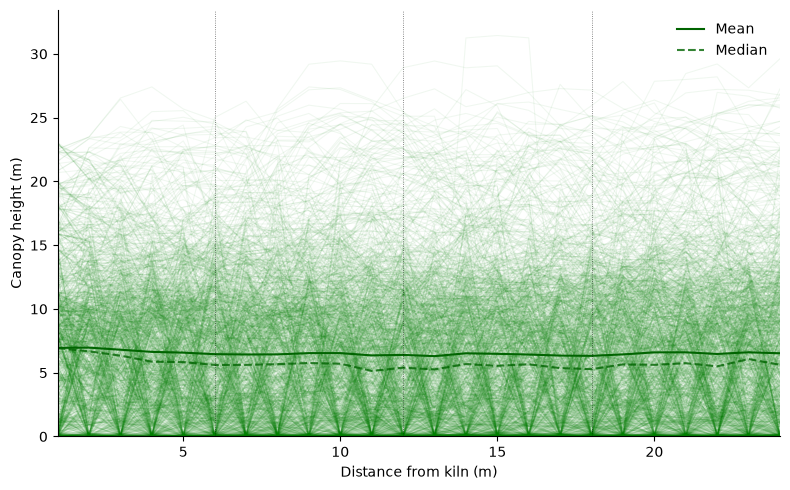

In [41]:
res_1 = plot_raw_rays(samples=samples, window_size=1, l_alpha=0.06)
res_1.savefig("results/merged_dem_rays16_step1_ring6x4/ray_profiles_raw.png", dpi=400)

This plot is very messy. Mainly due to the zig zag pattern at the bottom which is a result of pixels with value 0 representing the floor. There are a lot of rays that have floor pixels in the so this zig zag pattern cannot be avoided when plotting the raw pixel data.  

What can be seen is that on the very left, rays share pixel values due to the number of rays and the liimited number of pixels for small radii. This results in these few darker lines, indicating shared values. Once the radius is large enough that each ray has its own pixels, such artefacts disappear.  

**Floating average**  

What we can do is calculate a floating average for each pixel with a given window size. Let's try it with window size = 3 (i.e. it looks one pixel to the left and one to the right)

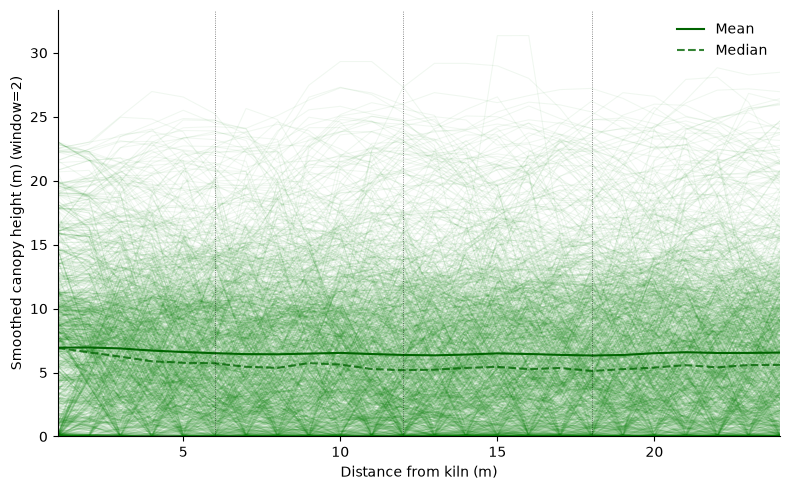

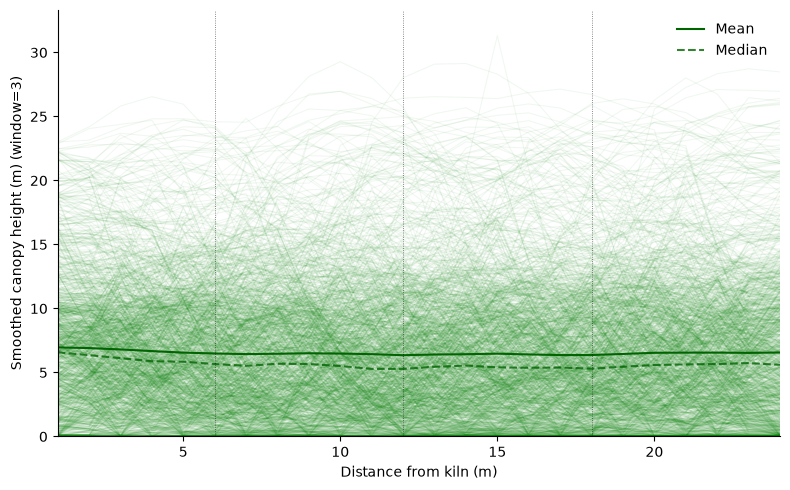

In [42]:
res_2 = plot_raw_rays(samples=samples, window_size=2, l_alpha=0.06)
res_3 = plot_raw_rays(samples=samples, window_size=3, l_alpha=0.06)

I don't know, whether these last 3 graphs are suitable for the report since the idea of this kind of graph is to truly show the data and how it looks like. The zig zag is not an artefact, it's part of the data. And the median and mean lines can still be interpreted well.